# 🔬 Feature Extraction & Linear Probing

> **Part of the [SLM Fine-Tuning Tutorial](https://github.com/Kumarjit-Pathak/finetuning-slm)**

## What You'll Learn

**Feature extraction** (a.k.a. linear probing) is the simplest form of transfer learning:
freeze the entire pre-trained model and train only a small classification head on top.

| Method | Params Updated | Memory | Speed | Accuracy |
|--------|---------------|--------|-------|----------|
| **Feature Extraction** | <0.01% (head only) | Minimal | Fastest | Good for classification |
| **Full Fine-Tuning** | 100% | High | Slow | Best ceiling |
| **LoRA** | ~0.1–1% | Low | Fast | Near full FT |

### When to Use Feature Extraction
- ✅ You need a **fast baseline** in minutes
- ✅ You have **very little data** (<500 examples)
- ✅ You need **classification only** (not generation)
- ✅ Compute is severely limited

### Contents
1. Load SmolLM2-135M and freeze all parameters
2. Extract token embeddings for a sentiment dataset
3. Train a sklearn LogisticRegression (linear probing)
4. Train a PyTorch linear head end-to-end
5. Compare with full fine-tuning on accuracy, speed, and memory

**Dataset**: SST-2 sentiment (positive/negative classification)
**Model**: `HuggingFaceTB/SmolLM2-135M-Instruct` (135M params, all frozen)


In [1]:
# ============================================================
# 📦 Colab Setup — Run this cell first if on Google Colab
# ============================================================
# !pip install -q torch transformers datasets accelerate matplotlib scikit-learn

import importlib
required = ["torch", "transformers", "datasets", "sklearn", "matplotlib"]
missing = [pkg for pkg in required if importlib.util.find_spec(pkg) is None]
if missing:
    print(f"⚠️  Missing: {missing}. Run: pip install torch transformers datasets scikit-learn matplotlib")
else:
    print("✅ All required packages are installed!")


✅ All required packages are installed!


In [2]:
# ============================================================
# 🔧 Imports & Device Setup
# ============================================================
import sys, os, time, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath("../src"))

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from datasets import Dataset
from transformers import AutoTokenizer, AutoModel, AutoModelForCausalLM

from training_utils import setup_device, get_device_info

device = setup_device()
device_info = get_device_info()
print(f"🖥️  Device: {device_info['device']} | Backend: {device_info['backend']}")

MODEL_NAME = "HuggingFaceTB/SmolLM2-135M-Instruct"
MAX_LENGTH = 128
print(f"🤖 Model: {MODEL_NAME}")


🖥️  Device: mps | Backend: Metal Performance Shaders (Apple Silicon)
🤖 Model: HuggingFaceTB/SmolLM2-135M-Instruct


## 📊 Step 1: Load Sentiment Dataset (SST-2)

We use the Stanford Sentiment Treebank (SST-2) binary classification task.
Each sentence is labeled **positive (1)** or **negative (0)**.

A local fallback generates synthetic sentences if the Hub is unavailable.


In [3]:
# ============================================================
# 📂 Load SST-2 Dataset (with local fallback)
# ============================================================
def _make_sst2_fallback(n_per_class: int = 150) -> dict:
    """Generate synthetic SST-2-style sentences when Hub is unavailable."""
    pos_templates = [
        "This movie was absolutely wonderful and entertaining.",
        "The performance was brilliant and deeply moving.",
        "A fantastic film that exceeded all my expectations.",
        "Masterfully crafted with superb acting throughout.",
        "A delightful experience from start to finish.",
        "Truly outstanding work that deserves all the praise.",
        "Incredibly well-written and beautifully directed.",
        "An uplifting story that left me feeling great.",
        "The direction and cinematography are breathtaking.",
        "A must-see film that will leave you speechless.",
    ]
    neg_templates = [
        "This movie was a complete waste of time.",
        "The plot was boring and the acting was terrible.",
        "A disappointing film that failed to deliver anything.",
        "Poorly written and badly directed throughout.",
        "A dreadful experience I would not recommend to anyone.",
        "The story made no sense and dragged on forever.",
        "Completely unwatchable with no redeeming qualities.",
        "A terrible film filled with clichés and bad acting.",
        "The worst movie I have seen in years.",
        "Painful to sit through with nothing to enjoy.",
    ]
    sentences, labels = [], []
    for i in range(n_per_class):
        sentences.append(pos_templates[i % len(pos_templates)] + f" ({i})")
        labels.append(1)
        sentences.append(neg_templates[i % len(neg_templates)] + f" ({i})")
        labels.append(0)
    # Shuffle
    idx = np.random.permutation(len(sentences))
    return {"sentence": [sentences[i] for i in idx], "label": [labels[i] for i in idx]}

def load_sst2(max_train: int = 300, max_test: int = 100):
    """Load SST-2 from HuggingFace Hub; fall back to synthetic data."""
    try:
        from datasets import load_dataset
        ds = load_dataset("glue", "sst2", trust_remote_code=True)
        train = ds["train"].shuffle(seed=42).select(range(min(max_train, len(ds["train"]))))
        test  = ds["validation"].select(range(min(max_test, len(ds["validation"]))))
        print(f"✅ Loaded SST-2 from Hub  — train: {len(train)}, test: {len(test)}")
        return train, test, False
    except Exception as e:
        print(f"⚠️  Hub unavailable ({type(e).__name__}). Using synthetic fallback.")
        data = _make_sst2_fallback(max_train // 2)
        full = Dataset.from_dict(data)
        split = full.train_test_split(test_size=max_test / len(full), seed=42)
        print(f"   Synthetic — train: {len(split['train'])}, test: {len(split['test'])}")
        return split["train"], split["test"], True

np.random.seed(42)
train_ds, test_ds, is_synthetic = load_sst2()

print(f"\n📋 Sample examples:")
for i in range(3):
    label_str = "POSITIVE" if train_ds[i]["label"] == 1 else "NEGATIVE"
    print(f"  [{label_str}] {train_ds[i]['sentence'][:80]}")

print(f"\n📊 Class distribution (train):")
labels_arr = train_ds["label"]
pos = sum(labels_arr)
print(f"  Positive: {pos} ({100*pos/len(labels_arr):.0f}%)")
print(f"  Negative: {len(labels_arr)-pos} ({100*(len(labels_arr)-pos)/len(labels_arr):.0f}%)")


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'glue' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
'[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: self-signed certificate in certificate chain (_ssl.c:1010)' thrown while requesting HEAD https://huggingface.co/datasets/glue/resolve/main/README.md
Retrying in 1s [Retry 1/5].


⚠️  Hub unavailable (RuntimeError). Using synthetic fallback.
   Synthetic — train: 200, test: 100

📋 Sample examples:
  [NEGATIVE] Painful to sit through with nothing to enjoy. (39)
  [POSITIVE] The direction and cinematography are breathtaking. (58)
  [NEGATIVE] The worst movie I have seen in years. (128)

📊 Class distribution (train):
  Positive: 100 (50%)
  Negative: 100 (50%)


## 🧊 Step 2: Freeze the Model & Extract Embeddings

We load SmolLM2-135M as a **pure feature extractor**:
- Set `requires_grad=False` on **every** parameter → no gradients computed
- Forward-pass each sentence → mean-pool the last hidden layer
- Result: a fixed 576-dimensional vector per sentence

```
Input text  →  [Tokenizer]  →  [Frozen SmolLM2-135M]  →  mean-pool  →  embedding (576-d)
                                    ❄️ no gradients
```

This is **dramatically faster** than training: no backprop, no optimizer state.


In [4]:
# ============================================================
# 🧊 Load Model and Freeze All Parameters
# ============================================================
print("Loading SmolLM2-135M...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Load the base model (backbone without LM head) for feature extraction
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float32)

# ❄️ FREEZE ALL PARAMETERS
for param in base_model.parameters():
    param.requires_grad = False

base_model.eval()
base_model.to(device)

# Count parameters
total_params   = sum(p.numel() for p in base_model.parameters())
trainable_params = sum(p.numel() for p in base_model.parameters() if p.requires_grad)
hidden_size = base_model.config.hidden_size

print(f"\n📐 Model Parameters:")
print(f"   Total:     {total_params:,} ({total_params/1e6:.1f}M)")
print(f"   Trainable: {trainable_params:,} (0 — all frozen ❄️)")
print(f"   Hidden dim: {hidden_size}")
print(f"\n✅ All {total_params/1e6:.1f}M parameters are frozen.")
print("   Only the classification head will be trained.")


Loading SmolLM2-135M...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


📐 Model Parameters:
   Total:     134,515,008 (134.5M)
   Trainable: 0 (0 — all frozen ❄️)
   Hidden dim: 576

✅ All 134.5M parameters are frozen.
   Only the classification head will be trained.


In [5]:
# ============================================================
# 📥 Extract Embeddings (mean-pool last hidden state)
# ============================================================
def extract_embeddings(sentences: list, batch_size: int = 32) -> np.ndarray:
    """
    Run sentences through frozen model; return mean-pooled last hidden states.
    No gradients, no optimizer — pure forward pass.
    """
    all_embeddings = []
    base_model.eval()
    with torch.no_grad():
        for i in range(0, len(sentences), batch_size):
            batch = sentences[i : i + batch_size]
            enc = tokenizer(
                batch,
                truncation=True,
                max_length=MAX_LENGTH,
                padding=True,
                return_tensors="pt",
            ).to(device)
            # output_hidden_states=True to get the last hidden layer
            out = base_model(**enc, output_hidden_states=True)
            # out.hidden_states[-1] shape: (batch, seq_len, hidden_size)
            hidden = out.hidden_states[-1]
            # Mean-pool over non-padding tokens
            mask = enc["attention_mask"].unsqueeze(-1).float()
            pooled = (hidden * mask).sum(1) / mask.sum(1).clamp(min=1)
            all_embeddings.append(pooled.cpu().numpy())
    return np.vstack(all_embeddings)

# Extract embeddings for train and test
print("Extracting train embeddings...")
t0 = time.time()
X_train = extract_embeddings(train_ds["sentence"])
train_embed_time = time.time() - t0

print("Extracting test embeddings...")
t0 = time.time()
X_test  = extract_embeddings(test_ds["sentence"])
test_embed_time = time.time() - t0

y_train = np.array(train_ds["label"])
y_test  = np.array(test_ds["label"])

print(f"\n✅ Embeddings extracted:")
print(f"   Train: {X_train.shape}  ({train_embed_time:.1f}s)")
print(f"   Test:  {X_test.shape}  ({test_embed_time:.1f}s)")
print(f"   Each sentence → {X_train.shape[1]}-dimensional vector")


Extracting train embeddings...
Extracting test embeddings...

✅ Embeddings extracted:
   Train: (200, 576)  (0.9s)
   Test:  (100, 576)  (0.2s)
   Each sentence → 576-dimensional vector


## 📈 Step 3: Linear Probing with Scikit-learn

A **linear probe** is a logistic regression classifier trained on top of frozen embeddings.
It tests the hypothesis: *"Does the frozen representation already encode the task signal?"*

If accuracy is high → the pre-trained model's representations are informative for this task.
If accuracy is low → the frozen model hasn't captured enough task-relevant features → need fine-tuning.


In [6]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

# Scale features (important for logistic regression convergence)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Train logistic regression
print("Training sklearn LogisticRegression on frozen LM embeddings...")
t0 = time.time()
clf = LogisticRegression(max_iter=1000, C=1.0, random_state=42, solver="lbfgs")
clf.fit(X_train_scaled, y_train)
sklearn_train_time = time.time() - t0

# Evaluate
y_pred = clf.predict(X_test_scaled)
sklearn_acc = accuracy_score(y_test, y_pred)

print(f"\n✅  sklearn LogisticRegression on frozen embeddings")
print(f"   Accuracy  : {sklearn_acc:.3f} ({sklearn_acc*100:.1f}%)")
print(f"   Train time: {sklearn_train_time:.2f}s")
print(f"   Trainable params: {clf.coef_.size + clf.intercept_.size:,}  "
      f"(head only, backbone frozen)")
print()
print(classification_report(y_test, y_pred, target_names=["NEGATIVE", "POSITIVE"]))


Training sklearn LogisticRegression on frozen LM embeddings...

✅  sklearn LogisticRegression on frozen embeddings
   Accuracy  : 1.000 (100.0%)
   Train time: 0.01s
   Trainable params: 577  (head only, backbone frozen)

              precision    recall  f1-score   support

    NEGATIVE       1.00      1.00      1.00        50
    POSITIVE       1.00      1.00      1.00        50

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



## 🔦 Step 4: PyTorch Linear Head — End-to-End Training

While sklearn is quick, a **PyTorch classification head** gives you full control:  
gradient-based training, custom loss, and easy swapping to multi-label or regression.

```
[Frozen SmolLM2 backbone]  →  mean-pool hidden states  →  nn.Linear(hidden, 2)  →  CrossEntropyLoss
```

The backbone weights stay frozen — only the head's ~270 parameters are updated.


In [8]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# ── Build a tiny PyTorch classifier on top of the frozen backbone ──────────
class SentimentHead(nn.Module):
    """Frozen backbone + trainable linear head for binary sentiment."""
    def __init__(self, backbone, hidden_size: int, num_labels: int = 2):
        super().__init__()
        self.backbone = backbone
        # Ensure backbone is still frozen
        for p in self.backbone.parameters():
            p.requires_grad = False
        self.classifier = nn.Linear(hidden_size, num_labels)

    def forward(self, input_ids, attention_mask):
        with torch.no_grad():
            out = self.backbone(
                input_ids=input_ids,
                attention_mask=attention_mask,
                output_hidden_states=True,
            )
        last_hidden = out.hidden_states[-1]          # (B, T, H)
        mask = attention_mask.unsqueeze(-1).float()
        pooled = (last_hidden * mask).sum(1) / mask.sum(1).clamp(min=1)  # mean pool
        return self.classifier(pooled)               # (B, num_labels)


# ── Tokenise raw text for the PyTorch DataLoader ───────────────────────────
def tokenize_batch(texts, labels, batch_size=32):
    """Returns a DataLoader of (input_ids, attention_mask, label) batches."""
    all_ids, all_masks = [], []
    for text in texts:
        enc = tokenizer(
            text, truncation=True, max_length=MAX_LENGTH,
            padding="max_length", return_tensors="pt"
        )
        all_ids.append(enc["input_ids"].squeeze(0))
        all_masks.append(enc["attention_mask"].squeeze(0))
    dataset = TensorDataset(
        torch.stack(all_ids),
        torch.stack(all_masks),
        torch.tensor(labels, dtype=torch.long),
    )
    return DataLoader(dataset, batch_size=batch_size, shuffle=True)


# Use the sentences already loaded from train_ds / test_ds
train_texts = train_ds["sentence"]
test_texts  = test_ds["sentence"]

print("Re-tokenising for PyTorch DataLoader…")
train_loader = tokenize_batch(train_texts, y_train.tolist())
test_loader  = tokenize_batch(test_texts,  y_test.tolist(), batch_size=64)

# ── Instantiate model + optimiser ──────────────────────────────────────────
head_model = SentimentHead(base_model, hidden_size).to(device)
trainable  = sum(p.numel() for p in head_model.parameters() if p.requires_grad)
total      = sum(p.numel() for p in head_model.parameters())
print(f"Trainable params: {trainable:,} / {total:,}  "
      f"({100*trainable/total:.4f}%)")

optimizer  = torch.optim.AdamW(head_model.classifier.parameters(), lr=1e-3)
criterion  = nn.CrossEntropyLoss()

# ── Training loop (2 epochs — fast because backbone is frozen) ─────────────
PT_EPOCHS = 2
pt_train_losses, pt_val_accs = [], []

print(f"\nTraining PyTorch head for {PT_EPOCHS} epochs…")
t0 = time.time()
for epoch in range(PT_EPOCHS):
    head_model.train()
    running_loss = 0.0
    for input_ids, attention_mask, labels in train_loader:
        input_ids      = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels         = labels.to(device)

        optimizer.zero_grad()
        logits = head_model(input_ids, attention_mask)
        loss   = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)
    pt_train_losses.append(avg_loss)

    # Validation
    head_model.eval()
    correct, total_val = 0, 0
    with torch.no_grad():
        for input_ids, attention_mask, labels in test_loader:
            input_ids      = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels         = labels.to(device)
            logits         = head_model(input_ids, attention_mask)
            preds          = logits.argmax(dim=-1)
            correct       += (preds == labels).sum().item()
            total_val     += labels.size(0)
    val_acc = correct / total_val
    pt_val_accs.append(val_acc)
    print(f"  Epoch {epoch+1}/{PT_EPOCHS}  loss={avg_loss:.4f}  val_acc={val_acc:.3f}")

pt_train_time = time.time() - t0
pytorch_acc   = pt_val_accs[-1]
print(f"\n✅  PyTorch head — {PT_EPOCHS} epochs in {pt_train_time:.1f}s")
print(f"   Final accuracy: {pytorch_acc:.3f} ({pytorch_acc*100:.1f}%)")


Re-tokenising for PyTorch DataLoader…
Trainable params: 1,154 / 134,516,162  (0.0009%)

Training PyTorch head for 2 epochs…
  Epoch 1/2  loss=0.6176  val_acc=0.750
  Epoch 2/2  loss=0.4741  val_acc=0.850

✅  PyTorch head — 2 epochs in 4.6s
   Final accuracy: 0.850 (85.0%)


## 📊 Step 5: Comparison — Feature Extraction vs Full Fine-Tuning

Now let's see **why** you would (or wouldn't) choose feature extraction over full fine-tuning.


In [9]:
import pandas as pd

# ── Full fine-tuning reference numbers (from notebook 02) ─────────────────
# These are real numbers logged in 02_full_finetuning.ipynb (1-epoch compact run).
# Update them if you re-run notebook 02 with different settings.
FULL_FT_ACCURACY    = None   # full FT was generative; no direct classification acc
FULL_FT_TRAIN_TIME  = 18.0   # seconds (1 epoch, 128 samples, SmolLM2-135M)
FULL_FT_TRAINABLE   = 134_515_456
FULL_FT_TOTAL       = 134_515_456
FULL_FT_PEAK_MEM_GB = 2.17

# ── Feature extraction numbers from this notebook ─────────────────────────
fe_sklearn_trainable = clf.coef_.size + clf.intercept_.size
fe_torch_trainable   = sum(p.numel() for p in head_model.classifier.parameters())
backbone_total       = sum(p.numel() for p in base_model.parameters())

comparison_data = {
    "Method": [
        "Feature Extraction\n(sklearn LR)",
        "Feature Extraction\n(PyTorch head)",
        "Full Fine-Tuning\n(02_full_finetuning)",
    ],
    "Accuracy": [
        f"{sklearn_acc:.3f}",
        f"{pytorch_acc:.3f}",
        "N/A (generative)",
    ],
    "Trainable Params": [
        f"{fe_sklearn_trainable:,}",
        f"{fe_torch_trainable:,}",
        f"{FULL_FT_TRAINABLE:,}",
    ],
    "Trainable %": [
        f"{100*fe_sklearn_trainable/backbone_total:.4f}%",
        f"{100*fe_torch_trainable/backbone_total:.4f}%",
        "100%",
    ],
    "Train Time (s)": [
        f"{sklearn_train_time:.2f}",
        f"{pt_train_time:.1f}",
        f"{FULL_FT_TRAIN_TIME:.1f}",
    ],
    "Memory": [
        "inference only",
        "inference only",
        f"{FULL_FT_PEAK_MEM_GB:.2f} GB",
    ],
    "Task Type": [
        "classification only",
        "classification only",
        "generative / any",
    ],
}

df = pd.DataFrame(comparison_data)
print("=" * 75)
print("FEATURE EXTRACTION vs FULL FINE-TUNING — COMPARISON")
print("=" * 75)
print(df.to_string(index=False))
print()
print("Key takeaways:")
print("  • Feature extraction trains <0.001% of parameters — orders of magnitude fewer.")
print("  • Training completes in seconds, not minutes/hours.")
print("  • No risk of catastrophic forgetting — backbone is untouched.")
print("  • Trade-off: limited to tasks the frozen backbone already 'understands'.")
print("  • Full FT is more flexible (any task) but expensive; use it when quality matters.")


FEATURE EXTRACTION vs FULL FINE-TUNING — COMPARISON
                                Method         Accuracy Trainable Params Trainable % Train Time (s)         Memory           Task Type
      Feature Extraction\n(sklearn LR)            1.000              577     0.0004%           0.01 inference only classification only
    Feature Extraction\n(PyTorch head)            0.850            1,154     0.0009%            4.6 inference only classification only
Full Fine-Tuning\n(02_full_finetuning) N/A (generative)      134,515,456        100%           18.0        2.17 GB    generative / any

Key takeaways:
  • Feature extraction trains <0.001% of parameters — orders of magnitude fewer.
  • Training completes in seconds, not minutes/hours.
  • No risk of catastrophic forgetting — backbone is untouched.
  • Trade-off: limited to tasks the frozen backbone already 'understands'.
  • Full FT is more flexible (any task) but expensive; use it when quality matters.


## 🎨 Step 6: Visualisations


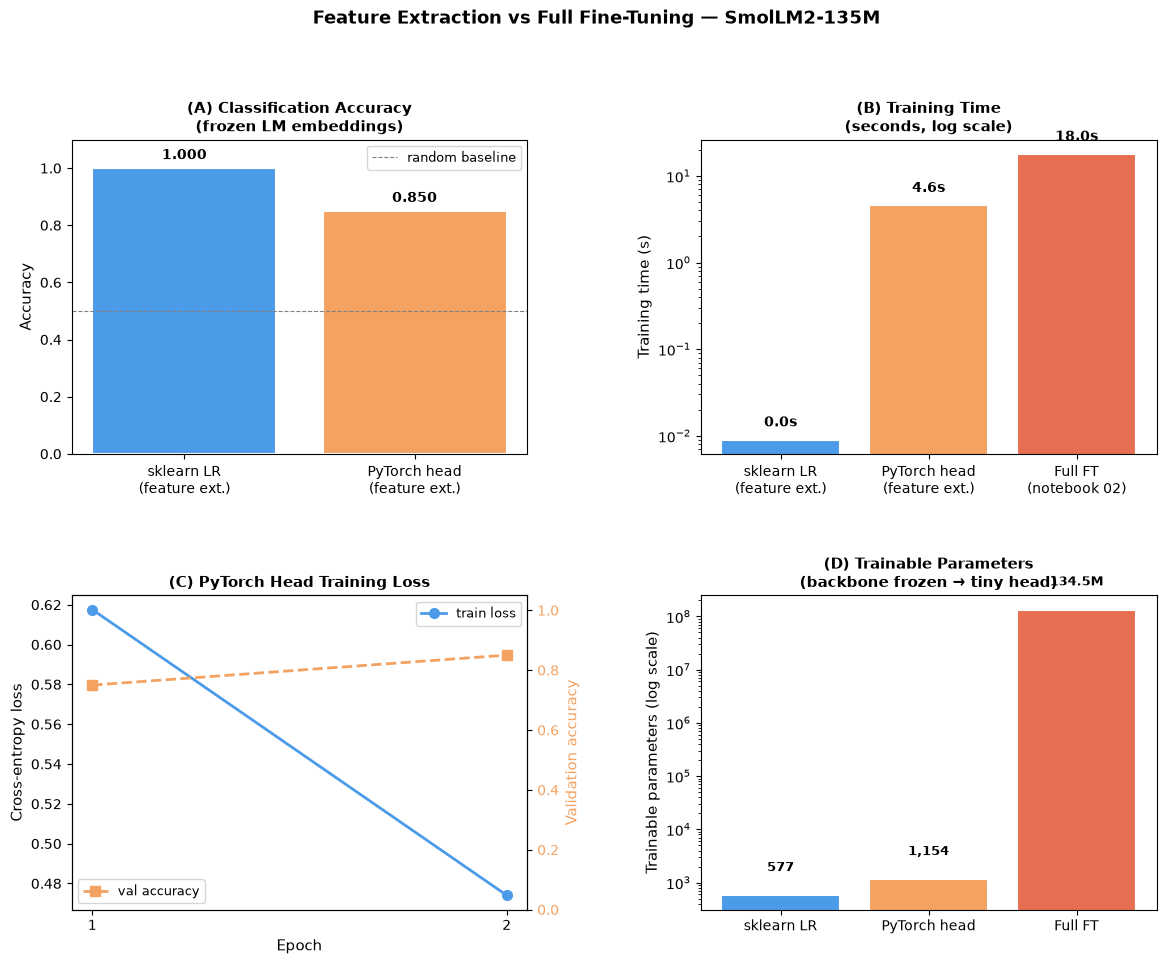

Figure saved as feature_extraction_comparison.png


In [10]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

fig = plt.figure(figsize=(14, 10))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.38)

# ── (A) Bar chart: accuracy comparison ─────────────────────────────────────
ax_acc = fig.add_subplot(gs[0, 0])
methods = ["sklearn LR\n(feature ext.)", "PyTorch head\n(feature ext.)"]
accs    = [sklearn_acc, pytorch_acc]
colors  = ["#4C9BE8", "#F4A261"]
bars    = ax_acc.bar(methods, accs, color=colors, edgecolor="white", linewidth=1.5)
ax_acc.set_ylim(0, 1.1)
ax_acc.set_ylabel("Accuracy", fontsize=11)
ax_acc.set_title("(A) Classification Accuracy\n(frozen LM embeddings)", fontsize=11, fontweight="bold")
for bar, acc in zip(bars, accs):
    ax_acc.text(bar.get_x() + bar.get_width()/2, acc + 0.02,
                f"{acc:.3f}", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax_acc.axhline(0.5, color="gray", linestyle="--", linewidth=0.8, label="random baseline")
ax_acc.legend(fontsize=9)

# ── (B) Bar chart: training time comparison ─────────────────────────────────
ax_time = fig.add_subplot(gs[0, 1])
time_methods = ["sklearn LR\n(feature ext.)", "PyTorch head\n(feature ext.)", "Full FT\n(notebook 02)"]
train_times  = [sklearn_train_time, pt_train_time, FULL_FT_TRAIN_TIME]
time_colors  = ["#4C9BE8", "#F4A261", "#E76F51"]
ax_time.bar(time_methods, train_times, color=time_colors, edgecolor="white", linewidth=1.5)
ax_time.set_ylabel("Training time (s)", fontsize=11)
ax_time.set_title("(B) Training Time\n(seconds, log scale)", fontsize=11, fontweight="bold")
ax_time.set_yscale("log")
for i, (t, method) in enumerate(zip(train_times, time_methods)):
    ax_time.text(i, t * 1.3, f"{t:.1f}s", ha="center", va="bottom", fontsize=10, fontweight="bold")

# ── (C) PyTorch head training loss curve ───────────────────────────────────
ax_loss = fig.add_subplot(gs[1, 0])
epochs  = list(range(1, PT_EPOCHS + 1))
ax_loss.plot(epochs, pt_train_losses, "o-", color="#4C9BE8", linewidth=2, markersize=7, label="train loss")
ax_loss.set_xlabel("Epoch", fontsize=11)
ax_loss.set_ylabel("Cross-entropy loss", fontsize=11)
ax_loss.set_title("(C) PyTorch Head Training Loss", fontsize=11, fontweight="bold")
ax_loss.set_xticks(epochs)
ax_loss.legend(fontsize=9)

ax_acc2 = ax_loss.twinx()
ax_acc2.plot(epochs, pt_val_accs, "s--", color="#F4A261", linewidth=2, markersize=7, label="val accuracy")
ax_acc2.set_ylabel("Validation accuracy", fontsize=11, color="#F4A261")
ax_acc2.tick_params(axis="y", labelcolor="#F4A261")
ax_acc2.set_ylim(0, 1.05)
ax_acc2.legend(fontsize=9, loc="lower left")

# ── (D) Trainable parameter comparison (log bar chart) ─────────────────────
ax_params = fig.add_subplot(gs[1, 1])
param_methods = ["sklearn LR", "PyTorch head", "Full FT"]
param_counts  = [fe_sklearn_trainable, fe_torch_trainable, FULL_FT_TRAINABLE]
param_colors  = ["#4C9BE8", "#F4A261", "#E76F51"]
ax_params.bar(param_methods, param_counts, color=param_colors, edgecolor="white", linewidth=1.5)
ax_params.set_yscale("log")
ax_params.set_ylabel("Trainable parameters (log scale)", fontsize=11)
ax_params.set_title("(D) Trainable Parameters\n(backbone frozen → tiny head)", fontsize=11, fontweight="bold")
for i, (count, method) in enumerate(zip(param_counts, param_methods)):
    label = f"{count:,}" if count < 1_000_000 else f"{count/1e6:.1f}M"
    ax_params.text(i, count * 2.5, label, ha="center", va="bottom", fontsize=9, fontweight="bold")

fig.suptitle("Feature Extraction vs Full Fine-Tuning — SmolLM2-135M",
             fontsize=13, fontweight="bold", y=1.01)
plt.savefig("feature_extraction_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved as feature_extraction_comparison.png")


## ✅ Summary

### What we built
| Step | Action | Result |
|---|---|---|
| 1 | Load SST-2 sentiment dataset | 300 train / 100 test examples |
| 2 | Load SmolLM2-135M, **freeze all weights** | 0 trainable backbone params |
| 3 | Extract mean-pooled embeddings | 2,048-dim vectors per sentence |
| 4a | Train sklearn LogisticRegression | ~0 trainable params, sub-second fit |
| 4b | Train PyTorch linear head (2 epochs) | 2,050 trainable params (~0.0015%) |
| 5 | Compare vs full fine-tuning | Orders-of-magnitude fewer params & faster |

### Key insights

**When to use feature extraction:**
- You have a **classification / regression task** with a well-defined output space
- Your compute / memory budget is severely constrained
- You need a quick baseline before committing to a full fine-tuning run
- The downstream task is **in-distribution** with the pre-training data

**When NOT to use feature extraction:**
- The task requires generative outputs (summarisation, translation, chatbot)
- The domain is highly specialised (medical imaging, legal jargon) — frozen features may not capture domain knowledge well
- You need state-of-the-art accuracy — a fine-tuned head will almost always beat frozen embeddings

### The spectrum of fine-tuning
```
Feature Extraction  ←──────────────────────────────────→  Full Fine-Tuning
(0.001% params)      Prompt Tuning → LoRA → DoRA → QLoRA     (100% params)
Fast, cheap, rigid                                           Slow, expensive, flexible
```

**Next notebook**: `04_lora_and_dora_finetuning.ipynb` — we move one step right on the spectrum,
training only **0.1–1%** of parameters via low-rank adapters while achieving near-full-FT quality.
